# Sensitivity to the number of internal deformation attempts

## Objective

This notebook studies the sensitivity of the model to the maximum number of
internal orientation proposals used when a round cell attempts to elongate,

$$
n_{\rm int}\in\{1,3,5,7,10\}.
$$

Unlike the integration timestep, $n_{\rm int}$ is **not a numerical
convergence parameter**. For a round cell, the model draws $n_{\rm int}$
candidate orientations, retains those whose maximum normalized overlap is below
the elongation threshold, and accepts the valid proposal with the smallest
maximum overlap (with random tie breaking). Increasing $n_{\rm int}$
therefore changes the effective deformation rule: it both increases the chance
of finding an admissible orientation and gives the cell more candidates from
which to select a low-overlap configuration.

The aim is deliberately narrow:

1. determine how strongly the late-time collective state depends on
   $n_{\rm int}$;
2. quantify how the round-cell elongation success probability changes with
   $n_{\rm int}$;
3. verify that overlap, instantaneous velocity and contraction-safety
   diagnostics remain regular;
4. identify whether the model reaches a practical plateau over the tested
   values and, if so, choose the **smallest** $n_{\rm int}$ within that
   plateau.

The campaign uses $N=1000$, $\kappa=2.5$,
$\lambda_{\rm core}=1$, $\Delta t=0.01$,
$\rho=\{0.75,0.80,0.84,0.90\}$, 64 realizations per density,
no noise, instantaneous deformation, deformation sweeps every $0.1$ units of
physical time, contraction overlap safety ratio $0.8$, and $T=2000$.

The $n_{\rm int}=1$ data are reused from the validated
$\lambda_{\rm core}=1,\Delta t=0.01$ timestep campaign. The four new
campaigns ($3,5,7,10$) passed the same file-level completeness checks before
processing.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

N_TARGET = 1000
KAPPA = 2.5
LAMBDA_CORE = 1.0
DELTA_T = 0.01

N_INTS = [1, 3, 5, 7, 10]
DENSITIES = [0.75, 0.80, 0.84, 0.90]

T_FINAL = 2000.0
T_LATE_MIN = 1500.0
N_INT_REFERENCE = 10
SELECTED_N_INT = 5
TIME_TOL = 1e-9

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25


## 1. Load the processed campaign

Only the five compact datasets needed for the parameter decision are loaded.
Raw cluster snapshots, cluster-size distributions, OVITO files and checkpoints
are not needed here.

The processed directory is expected to have the structure

```text
processed/
├── attempts_1/
├── attempts_3/
├── attempts_5/
├── attempts_7/
└── attempts_10/
```

with the usual `order_parameters`, `motion`, `overlap`, `deformation` and
`clusters` subdirectories inside each case.


In [2]:
def find_processed_dir():
    candidates = [
        Path("processed"),
        Path("preliminary/def_attempts/processed"),
    ]
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError(
        "Could not find the processed directory. "
        "Run from the repository root or from preliminary/def_attempts."
    )


PROCESSED_DIR = find_processed_dir()


def load_attempt_sweep(relative_path):
    tables = []

    for n_int in N_INTS:
        path = PROCESSED_DIR / f"attempts_{n_int}" / relative_path
        data = pd.read_parquet(path).copy()
        data["n_int"] = n_int
        tables.append(data)

    return pd.concat(tables, ignore_index=True)


order_parameters = load_attempt_sweep(
    Path("order_parameters") / "order_parameters.parquet"
)
motion = load_attempt_sweep(
    Path("motion") / "motion.parquet"
)
overlap = load_attempt_sweep(
    Path("overlap") / "overlap.parquet"
)
deformation = load_attempt_sweep(
    Path("deformation") / "deformation.parquet"
)
clusters = load_attempt_sweep(
    Path("clusters") / "cluster_time_series.parquet"
)

print("Processed directory:", PROCESSED_DIR)
for name, data in {
    "order": order_parameters,
    "motion": motion,
    "overlap": overlap,
    "deformation": deformation,
    "clusters": clusters,
}.items():
    print(f"{name:12s}: {len(data):,} rows")

figures_dir = Path("figures")
if not figures_dir.exists():
    figures_dir.mkdir(parents=True)

Processed directory: processed
order       : 129,280 rows
motion      : 129,280 rows
overlap     : 51,200 rows
deformation : 51,200 rows
clusters    : 419,840 rows


In [3]:
def select_campaign(data):
    rho_mask = np.logical_or.reduce(
        [np.isclose(data["rho"], rho) for rho in DENSITIES]
    )

    mask = (
        (data["N"] == N_TARGET)
        & np.isclose(data["kappa"], KAPPA)
        & np.isclose(data["lambda_core"], LAMBDA_CORE)
        & np.isclose(data["delta_t"], DELTA_T)
        & np.isclose(data["initial_fraction_elongated"], 0.0)
        & rho_mask
        & data["n_int"].isin(N_INTS)
    )

    return data.loc[mask].copy()


order_parameters = select_campaign(order_parameters)
motion = select_campaign(motion)
overlap = select_campaign(overlap)
deformation = select_campaign(deformation)
clusters = select_campaign(clusters)

print("n_int:", np.sort(order_parameters["n_int"].unique()))
print("lambda_core:", np.sort(order_parameters["lambda_core"].unique()))
print("delta_t:", np.sort(order_parameters["delta_t"].unique()))
print("rho:", np.sort(order_parameters["rho"].unique()))

seed_counts = (
    order_parameters
    .groupby(["n_int", "rho"])["seed"]
    .nunique()
)

print(
    "Realizations per (n_int, rho):",
    seed_counts.min(),
    "to",
    seed_counts.max(),
)
display(seed_counts.unstack("rho"))


n_int: [ 1  3  5  7 10]
lambda_core: [1.]
delta_t: [0.01]
rho: [0.75 0.8  0.84 0.9 ]
Realizations per (n_int, rho): 64 to 64


rho,0.75,0.80,0.84,0.90
n_int,,,,
1,64,64,64,64
3,64,64,64,64
5,64,64,64,64
7,64,64,64,64
10,64,64,64,64


## 2. Is the late-time window reasonable?

As in the timestep study, late-time averages use

$$
1500\le t\le2000.
$$

Here it is useful to inspect all tested values of $n_{\rm int}$, because the
parameter may alter not only the asymptotic state but also the relaxation
toward it.

This remains a **late-time window**, not a claim that every density is strictly
stationary. In particular, the highest-density regime may retain slow
evolution.


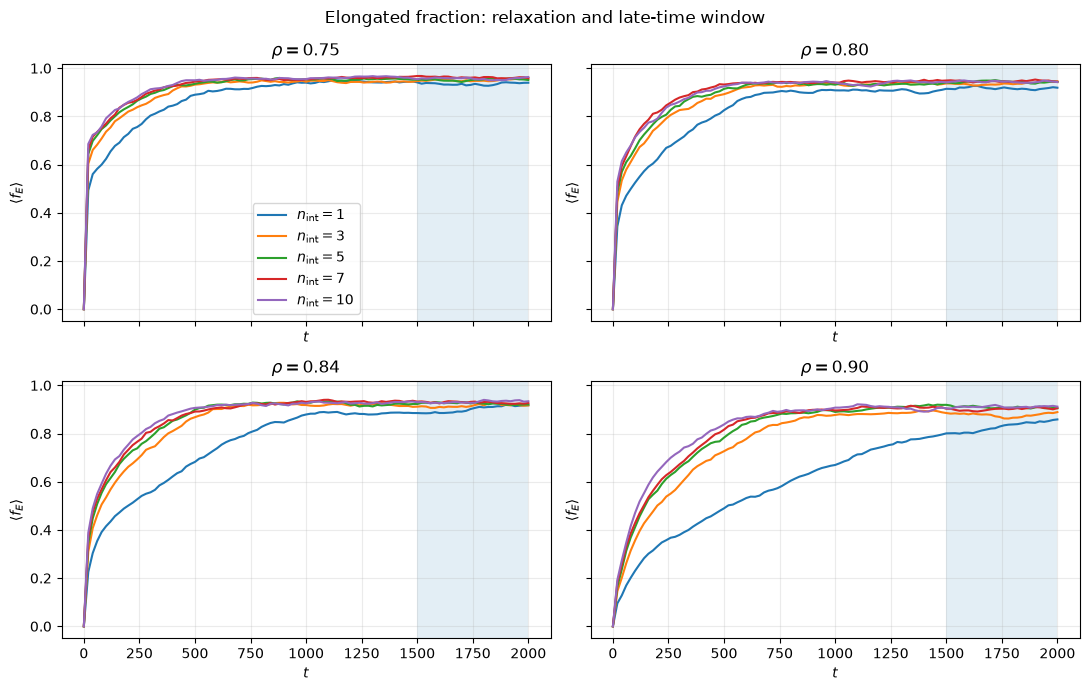

In [4]:
fe_time = (
    order_parameters
    .groupby(["n_int", "rho", "time"])["fraction_elongated"]
    .mean()
    .reset_index()
)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(11, 7),
    sharex=True,
    sharey=True,
)
axes = axes.ravel()

for ax, rho in zip(axes, DENSITIES):
    subset_rho = fe_time[np.isclose(fe_time["rho"], rho)]

    for n_int in N_INTS:
        subset = (
            subset_rho[subset_rho["n_int"] == n_int]
            .sort_values("time")
        )
        ax.plot(
            subset["time"],
            subset["fraction_elongated"],
            label=fr"$n_{{\rm int}}={n_int}$",
        )

    ax.axvspan(T_LATE_MIN, T_FINAL, alpha=0.12)
    ax.set_title(fr"$\rho={rho:.2f}$")
    ax.set_xlabel(r"$t$")
    ax.set_ylabel(r"$\langle f_E\rangle$")

axes[0].legend()
fig.suptitle("Elongated fraction: relaxation and late-time window")
fig.tight_layout()
plt.savefig(figures_dir / "elongated_fraction_relaxation.png", dpi=300)
plt.show()


## 3. Late-time collective state

Four bounded observables summarize the collective state:

- elongated fraction $f_E$;
- polar order $P$;
- nematic order $Q$;
- fraction $S_{1,E}/N_E$ of elongated cells in the largest spatial
  elongated cluster.

For each realization, each observable is first averaged over the late-time
window. We then compare the **ensemble mean $\pm$ SEM** across the 64
realizations.

There is no exact $n_{\rm int}\to0$ or $n_{\rm int}\to\infty$ numerical
reference analogous to the timestep study. The largest tested value,
$n_{\rm int}=10$, is therefore used only as a **practical comparison
reference**, not as ground truth.


In [5]:
order_late = order_parameters[
    (order_parameters["time"] >= T_LATE_MIN)
    & (order_parameters["time"] <= T_FINAL + TIME_TOL)
].copy()

order_per_seed = (
    order_late
    .groupby(["n_int", "rho", "seed"], as_index=False)
    .agg(
        f_E=("fraction_elongated", "mean"),
        P=("polar", "mean"),
        Q=("nematic", "mean"),
    )
)

elongated_spatial = clusters[
    (clusters["phenotype"] == "elongated")
    & (clusters["alignment"] == "spatial")
    & np.isclose(clusters["range_factor"], 1.0)
    & (clusters["time"] >= T_LATE_MIN)
    & (clusters["time"] <= T_FINAL + TIME_TOL)
].copy()

cluster_per_seed = (
    elongated_spatial
    .groupby(["n_int", "rho", "seed"], as_index=False)
    .agg(S1E_over_NE=("S1_over_Nphenotype", "mean"))
)

macro_per_seed = order_per_seed.merge(
    cluster_per_seed,
    on=["n_int", "rho", "seed"],
    how="inner",
)

MACRO_METRICS = ["f_E", "P", "Q", "S1E_over_NE"]

macro_long = macro_per_seed.melt(
    id_vars=["n_int", "rho", "seed"],
    value_vars=MACRO_METRICS,
    var_name="metric",
    value_name="value",
)

macro_summary = (
    macro_long
    .groupby(["n_int", "rho", "metric"])
    .agg(mean=("value", "mean"), sem=("value", "sem"))
    .reset_index()
)

display(
    macro_summary
    .pivot_table(
        index=["n_int", "rho"],
        columns="metric",
        values="mean",
    )
    .round(4)
)


metric           P       Q  S1E_over_NE     f_E
n_int rho                                      
1     0.75  0.6330  0.3530       0.8662  0.9351
      0.80  0.5880  0.2863       0.8786  0.9169
      0.84  0.5996  0.3009       0.8872  0.9009
      0.90  0.5577  0.2802       0.8598  0.8274
3     0.75  0.6359  0.3472       0.8657  0.9505
      0.80  0.6201  0.3511       0.8838  0.9363
      0.84  0.5680  0.2716       0.8928  0.9156
      0.90  0.5543  0.2716       0.8942  0.8774
5     0.75  0.6221  0.3387       0.8757  0.9522
      0.80  0.6181  0.3379       0.8889  0.9433
      0.84  0.5946  0.3124       0.8921  0.9247
      0.90  0.5874  0.3010       0.9047  0.9090
7     0.75  0.6562  0.3765       0.8786  0.9622
      0.80  0.6185  0.3377       0.8903  0.9464
      0.84  0.5812  0.2959       0.8966  0.9289
      0.90  0.5813  0.2927       0.9083  0.9012
10    0.75  0.6399  0.3899       0.8568  0.9569
      0.80  0.6130  0.3298       0.8883  0.9441
      0.84  0.6072  0.3239       0.8954  0.9317
      0.90  0.5994  0.3081       0.9102  0.9107

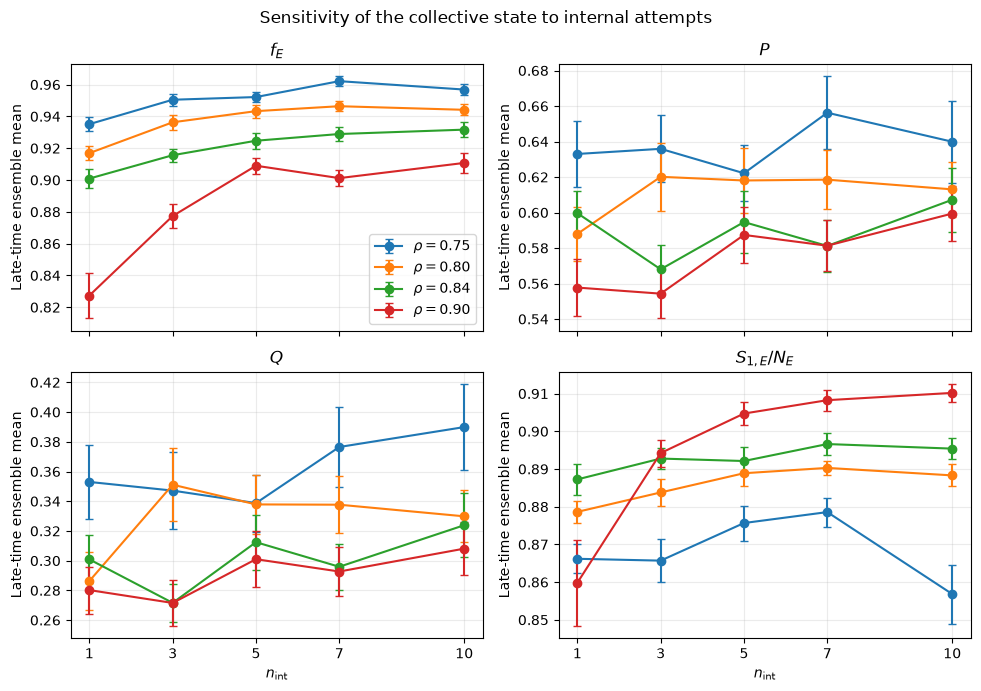

In [6]:
metric_labels = {
    "f_E": r"$f_E$",
    "P": r"$P$",
    "Q": r"$Q$",
    "S1E_over_NE": r"$S_{1,E}/N_E$",
}

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10, 7),
    sharex=True,
)
axes = axes.ravel()

for ax, metric in zip(axes, MACRO_METRICS):
    for rho in DENSITIES:
        subset = (
            macro_summary[
                (macro_summary["metric"] == metric)
                & np.isclose(macro_summary["rho"], rho)
            ]
            .sort_values("n_int")
        )

        ax.errorbar(
            subset["n_int"],
            subset["mean"],
            yerr=subset["sem"],
            marker="o",
            capsize=3,
            label=fr"$\rho={rho:.2f}$",
        )

    ax.set_title(metric_labels[metric])
    ax.set_ylabel("Late-time ensemble mean")
    ax.set_xticks(N_INTS)

for ax in axes[-2:]:
    ax.set_xlabel(r"$n_{\rm int}$")

axes[0].legend()
fig.suptitle("Sensitivity of the collective state to internal attempts")
fig.tight_layout()
plt.savefig(figures_dir / "macro_metrics_vs_n_int.png", dpi=300)
plt.show()


In [7]:
reference_macro = (
    macro_summary[macro_summary["n_int"] == N_INT_REFERENCE]
    [["rho", "metric", "mean"]]
    .rename(columns={"mean": "reference_mean"})
)

macro_vs_reference = macro_summary.merge(
    reference_macro,
    on=["rho", "metric"],
    how="inner",
)

macro_vs_reference["abs_mean_shift"] = np.abs(
    macro_vs_reference["mean"]
    - macro_vs_reference["reference_mean"]
)

macro_shift_to_10 = (
    macro_vs_reference
    .groupby(["n_int", "metric"])["abs_mean_shift"]
    .max()
    .unstack("metric")
    .reindex(N_INTS)
)

macro_shift_to_10["overall_max"] = macro_shift_to_10.max(axis=1)

print(
    "Maximum across densities of "
    "|ensemble mean(n_int) - ensemble mean(n_int=10)|:"
)
display(macro_shift_to_10.round(4))


Maximum across densities of |ensemble mean(n_int) - ensemble mean(n_int=10)|:


metric,P,Q,S1E_over_NE,f_E,overall_max
n_int,,,,,
1,0.0417,0.0435,0.0504,0.0834,0.0834
3,0.0451,0.0523,0.0160,0.0334,0.0523
5,0.0178,0.0512,0.0188,0.0070,0.0512
7,0.0260,0.0280,0.0217,0.0096,0.0280
10,0.0000,0.0000,0.0000,0.0000,0.0000


In [8]:
summary_sorted = macro_summary.sort_values(
    ["rho", "metric", "n_int"]
).copy()

summary_sorted["previous_n_int"] = (
    summary_sorted.groupby(["rho", "metric"])["n_int"].shift()
)
summary_sorted["previous_mean"] = (
    summary_sorted.groupby(["rho", "metric"])["mean"].shift()
)
summary_sorted["successive_shift"] = np.abs(
    summary_sorted["mean"] - summary_sorted["previous_mean"]
)

successive_macro = (
    summary_sorted.dropna(subset=["successive_shift"])
    .groupby(["n_int", "metric"])["successive_shift"]
    .max()
    .unstack("metric")
    .reindex(N_INTS)
)

successive_macro["overall_max"] = successive_macro.max(axis=1)

print("Maximum across densities of successive ensemble-mean changes:")
display(successive_macro.round(4))


Maximum across densities of successive ensemble-mean changes:


metric,P,Q,S1E_over_NE,f_E,overall_max
n_int,,,,,
1,NaN,NaN,NaN,NaN,NaN
3,0.0322,0.0648,0.0344,0.0500,0.0648
5,0.0331,0.0408,0.0105,0.0316,0.0408
7,0.0341,0.0378,0.0045,0.0100,0.0378
10,0.0260,0.0280,0.0217,0.0096,0.0280


## 4. What does increasing $n_{\rm int}$ do to deformation?

The deformation counters record **cell-level deformation calls**, not the
number of candidate orientations tested inside each call. Thus

`round_elongation_attempts`

counts how many round cells were asked to elongate, while one such call
internally evaluates $n_{\rm int}$ candidate orientations.

The most direct empirical measure of the effect of $n_{\rm int}$ is therefore

$$
p_{\rm elong}
=
\frac{\sum_{\rm seeds}N_{\rm round\to elongated}}
     {\sum_{\rm seeds}N_{\rm round\ elongation\ calls}}.
$$

We use this **pooled estimator** rather than the unweighted mean of the
per-realization ratios. The latter can be biased upward when a realization has
few available round-cell attempts, because a large ratio from a small
denominator receives the same weight as a ratio based on many attempts.
Uncertainties on the pooled estimator are obtained by bootstrapping
realizations.

We also inspect elongation and contraction-to-round event rates per unit
physical time. In the late-time regime these two fluxes should be close if the
phenotypic composition is fluctuating around a dynamical balance rather than
drifting systematically.


In [9]:
deformation_late = deformation[
    (deformation["time_start"] >= T_LATE_MIN)
    & (deformation["time_end"] <= T_FINAL + TIME_TOL)
].copy()

deformation_per_seed = (
    deformation_late
    .groupby(["n_int", "rho", "seed"], as_index=False)
    .agg(
        interval_duration=("interval_duration", "sum"),
        round_attempts=("round_elongation_attempts", "sum"),
        round_successes=("round_elongation_successes", "sum"),
        elliptical_attempts=("elliptical_elongation_attempts", "sum"),
        elliptical_successes=("elliptical_elongation_successes", "sum"),
        contraction_events=("contraction_events", "sum"),
        contraction_to_round=("contraction_to_round_events", "sum"),
        contraction_attempts=("contraction_attempts", "sum"),
        contraction_rejections=(
            "contraction_overlap_rejections",
            "sum",
        ),
    )
)

deformation_per_seed["round_success_fraction"] = np.where(
    deformation_per_seed["round_attempts"] > 0,
    deformation_per_seed["round_successes"]
    / deformation_per_seed["round_attempts"],
    np.nan,
)

deformation_per_seed["round_attempt_rate"] = (
    deformation_per_seed["round_attempts"]
    / deformation_per_seed["interval_duration"]
)

deformation_per_seed["round_success_rate"] = (
    deformation_per_seed["round_successes"]
    / deformation_per_seed["interval_duration"]
)

deformation_per_seed["contraction_to_round_rate"] = (
    deformation_per_seed["contraction_to_round"]
    / deformation_per_seed["interval_duration"]
)

deformation_per_seed["contraction_rejection_fraction"] = np.where(
    deformation_per_seed["contraction_attempts"] > 0,
    deformation_per_seed["contraction_rejections"]
    / deformation_per_seed["contraction_attempts"],
    np.nan,
)

print(
    "Total late-time elliptical elongation calls:",
    int(deformation_per_seed["elliptical_attempts"].sum()),
)

DEFORMATION_METRICS = [
    "round_success_fraction",
    "round_attempt_rate",
    "round_success_rate",
    "contraction_to_round_rate",
    "contraction_rejection_fraction",
]

deformation_summary = (
    deformation_per_seed
    .groupby(["n_int", "rho"])[DEFORMATION_METRICS]
    .agg(["mean", "sem"])
)

display(deformation_summary.round(4))


Total late-time elliptical elongation calls: 0


round_success_fraction         round_attempt_rate            \
                             mean     sem               mean       sem   
n_int rho                                                                
1     0.75                 0.0046  0.0002           651.1045   43.7780   
      0.80                 0.0042  0.0001           829.6655   44.8447   
      0.84                 0.0038  0.0001           992.3578   59.8774   
      0.90                 0.0030  0.0001          1730.1468  144.6875   
3     0.75                 0.0060  0.0002           495.5492   37.0205   
      0.80                 0.0048  0.0002           638.6698   46.0109   
      0.84                 0.0046  0.0001           843.1340   41.5604   
      0.90                 0.0038  0.0001          1230.8715   74.1375   
5     0.75                 0.0060  0.0002           478.5692   30.4214   
      0.80                 0.0097  0.0040           566.7232   40.4988   
      0.84                 0.0050  0.0002           752.2936   50.6724   
      0.90                 0.0042  0.0001           910.8362   52.5056   
7     0.75                 0.0061  0.0002           378.8480   30.0769   
      0.80                 0.0057  0.0001           535.1167   33.1066   
      0.84                 0.0054  0.0001           711.3283   45.1159   
      0.90                 0.0042  0.0001           986.7771   50.3647   
10    0.75                 0.0070  0.0006           432.4554   35.5692   
      0.80                 0.0058  0.0001           557.4266   33.6607   
      0.84                 0.0052  0.0001           684.9863   47.9321   
      0.90                 0.0047  0.0001           891.7918   61.3780   

           round_success_rate         contraction_to_round_rate          \
                         mean     sem                      mean     sem   
n_int rho                                                                 
1     0.75             2.8915  0.1711                    2.8944  0.1709   
      0.80             3.3990  0.1553                    3.3899  0.1550   
      0.84             3.6046  0.1595                    3.5393  0.1532   
      0.90             4.3990  0.1764                    4.2832  0.1676   
3     0.75             2.7542  0.1791                    2.7316  0.1788   
      0.80             3.0415  0.1804                    3.0245  0.1822   
      0.84             3.7008  0.1312                    3.6904  0.1308   
      0.90             4.3242  0.1793                    4.3167  0.1787   
5     0.75             2.7755  0.1467                    2.7775  0.1484   
      0.80             2.9924  0.1703                    2.9881  0.1671   
      0.84             3.4697  0.1899                    3.4737  0.1895   
      0.90             3.6908  0.1665                    3.7188  0.1673   
7     0.75             2.3330  0.1682                    2.3507  0.1690   
      0.80             2.9856  0.1593                    2.9957  0.1597   
      0.84             3.5488  0.1787                    3.5601  0.1784   
      0.90             3.8870  0.1535                    3.8823  0.1557   
10    0.75             2.6483  0.1999                    2.6299  0.1981   
      0.80             3.0931  0.1535                    3.0903  0.1562   
      0.84             3.4548  0.1912                    3.4472  0.1902   
      0.90             3.8473  0.1951                    3.8334  0.1949   

           contraction_rejection_fraction          
                                     mean     sem  
n_int rho                                          
1     0.75                         0.0060  0.0009  
      0.80                         0.0058  0.0007  
      0.84                         0.0059  0.0006  
      0.90                         0.0064  0.0009  
3     0.75                         0.0041  0.0006  
      0.80                         0.0063  0.0008  
      0.84                         0.0062  0.0010  
      0.90                         0.0101  0.0016  
5     0.75

In [10]:
BOOTSTRAP_SAMPLES = 5000

pooled_rows = []

for (n_int, rho), group in deformation_per_seed.groupby(
    ["n_int", "rho"],
    sort=True,
):
    attempts = group["round_attempts"].to_numpy(dtype=float)
    successes = group["round_successes"].to_numpy(dtype=float)

    pooled_success = successes.sum() / attempts.sum()

    # Resample whole realizations so that within-seed temporal correlations
    # remain intact.
    rng_seed = (
        20261031
        + 1000 * int(n_int)
        + int(round(100 * float(rho)))
    )
    rng = np.random.default_rng(rng_seed)

    bootstrap_index = rng.integers(
        0,
        len(group),
        size=(BOOTSTRAP_SAMPLES, len(group)),
    )

    bootstrap_attempts = attempts[bootstrap_index].sum(axis=1)
    bootstrap_successes = successes[bootstrap_index].sum(axis=1)

    bootstrap_values = np.divide(
        bootstrap_successes,
        bootstrap_attempts,
        out=np.full(BOOTSTRAP_SAMPLES, np.nan),
        where=bootstrap_attempts > 0,
    )

    pooled_rows.append(
        {
            "n_int": n_int,
            "rho": rho,
            "pooled_success_fraction": pooled_success,
            "bootstrap_sem": np.nanstd(
                bootstrap_values,
                ddof=1,
            ),
            "ci95_low": np.nanpercentile(
                bootstrap_values,
                2.5,
            ),
            "ci95_high": np.nanpercentile(
                bootstrap_values,
                97.5,
            ),
        }
    )

round_success_pooled = pd.DataFrame(pooled_rows)

display(
    round_success_pooled
    .pivot_table(
        index="n_int",
        columns="rho",
        values="pooled_success_fraction",
    )
    .round(6)
)


rho,0.75,0.80,0.84,0.90
n_int,,,,
1,0.004441,0.004097,0.003632,0.002543
3,0.005558,0.004762,0.004389,0.003513
5,0.005800,0.005280,0.004612,0.004052
7,0.006158,0.005579,0.004989,0.003939
10,0.006124,0.005549,0.005044,0.004314


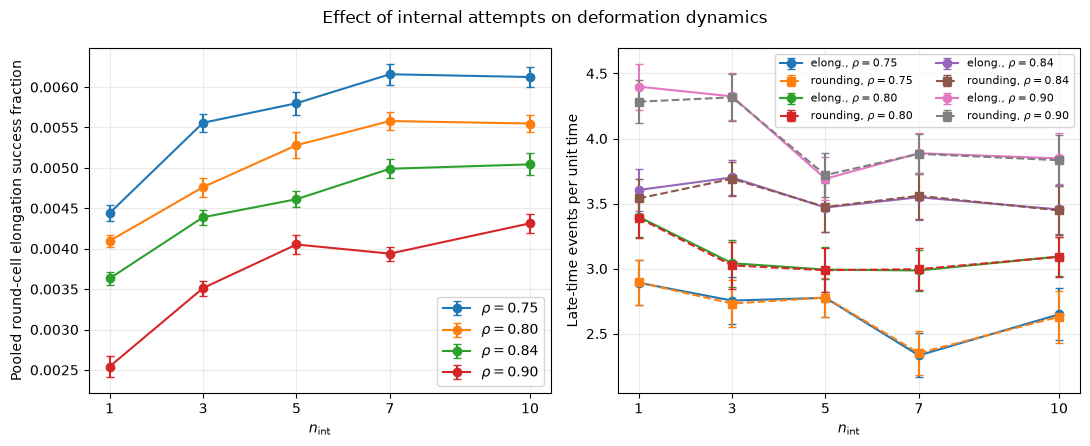

In [11]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4.5),
)

for rho in DENSITIES:
    pooled_subset = (
        round_success_pooled[
            np.isclose(round_success_pooled["rho"], rho)
        ]
        .sort_values("n_int")
    )

    axes[0].errorbar(
        pooled_subset["n_int"],
        pooled_subset["pooled_success_fraction"],
        yerr=pooled_subset["bootstrap_sem"],
        marker="o",
        capsize=3,
        label=fr"$\rho={rho:.2f}$",
    )

    rate_subset = (
        deformation_per_seed[
            np.isclose(deformation_per_seed["rho"], rho)
        ]
        .groupby("n_int")
        .agg(
            elong_rate_mean=("round_success_rate", "mean"),
            elong_rate_sem=("round_success_rate", "sem"),
            contraction_rate_mean=(
                "contraction_to_round_rate",
                "mean",
            ),
            contraction_rate_sem=(
                "contraction_to_round_rate",
                "sem",
            ),
        )
        .reindex(N_INTS)
    )

    axes[1].errorbar(
        rate_subset.index,
        rate_subset["elong_rate_mean"],
        yerr=rate_subset["elong_rate_sem"],
        marker="o",
        capsize=3,
        label=fr"elong., $\rho={rho:.2f}$",
    )
    axes[1].errorbar(
        rate_subset.index,
        rate_subset["contraction_rate_mean"],
        yerr=rate_subset["contraction_rate_sem"],
        marker="s",
        linestyle="--",
        capsize=3,
        label=fr"rounding, $\rho={rho:.2f}$",
    )

axes[0].set_xlabel(r"$n_{\rm int}$")
axes[0].set_ylabel("Pooled round-cell elongation success fraction")
axes[0].set_xticks(N_INTS)
axes[0].legend()

axes[1].set_xlabel(r"$n_{\rm int}$")
axes[1].set_ylabel("Late-time events per unit time")
axes[1].set_xticks(N_INTS)
axes[1].legend(ncol=2, fontsize=8)

fig.suptitle("Effect of internal attempts on deformation dynamics")
fig.tight_layout()
plt.savefig(figures_dir / "deformation_dynamics_vs_n_int.png", dpi=300)
plt.show()


In [12]:
round_success_reference = (
    round_success_pooled[
        round_success_pooled["n_int"] == N_INT_REFERENCE
    ][["rho", "pooled_success_fraction"]]
    .rename(
        columns={
            "pooled_success_fraction": "reference_success_fraction"
        }
    )
)

round_success_vs_reference = round_success_pooled.merge(
    round_success_reference,
    on="rho",
    how="inner",
)

round_success_vs_reference["abs_shift"] = np.abs(
    round_success_vs_reference["pooled_success_fraction"]
    - round_success_vs_reference["reference_success_fraction"]
)

round_success_shift_to_10 = (
    round_success_vs_reference
    .groupby("n_int")["abs_shift"]
    .max()
    .reindex(N_INTS)
    .rename("round_success_max_shift_to_10")
)

flux_balance = (
    deformation_per_seed
    .groupby(["n_int", "rho"])
    .agg(
        elongation_rate=("round_success_rate", "mean"),
        elongation_rate_sem=("round_success_rate", "sem"),
        contraction_to_round_rate=(
            "contraction_to_round_rate",
            "mean",
        ),
        contraction_to_round_rate_sem=(
            "contraction_to_round_rate",
            "sem",
        ),
    )
    .reset_index()
)

flux_balance["absolute_flux_difference"] = np.abs(
    flux_balance["elongation_rate"]
    - flux_balance["contraction_to_round_rate"]
)

flux_balance["relative_flux_imbalance"] = np.divide(
    2 * flux_balance["absolute_flux_difference"],
    (
        flux_balance["elongation_rate"]
        + flux_balance["contraction_to_round_rate"]
    ),
    out=np.full(len(flux_balance), np.nan),
    where=(
        flux_balance["elongation_rate"]
        + flux_balance["contraction_to_round_rate"]
    ) > 0,
)

print(
    "Maximum across densities of the pooled elongation-success "
    "shift relative to n_int=10:"
)
display(round_success_shift_to_10.to_frame().round(6))

print("\nLate-time elongation <-> contraction-to-round flux balance:")
display(
    flux_balance[
        [
            "n_int",
            "rho",
            "elongation_rate",
            "contraction_to_round_rate",
            "absolute_flux_difference",
            "relative_flux_imbalance",
        ]
    ].round(4)
)


Maximum across densities of the pooled elongation-success shift relative to n_int=10:


,round_success_max_shift_to_10
n_int,
1,0.001772
3,0.000801
5,0.000431
7,0.000375
10,0.000000



Late-time elongation <-> contraction-to-round flux balance:


,n_int,rho,elongation_rate,contraction_to_round_rate,absolute_flux_difference,relative_flux_imbalance
0,1,0.75,2.8915,2.8944,0.0029,0.0010
1,1,0.80,3.3990,3.3899,0.0091,0.0027
2,1,0.84,3.6046,3.5393,0.0653,0.0183
3,1,0.90,4.3990,4.2832,0.1157,0.0267
4,3,0.75,2.7542,2.7316,0.0227,0.0083
5,3,0.80,3.0415,3.0245,0.0170,0.0056
6,3,0.84,3.7008,3.6904,0.0104,0.0028
7,3,0.90,4.3242,4.3167,0.0075,0.0017
8,5,0.75,2.7755,2.7775,0.0020,0.0007
9,5,0.80,2.9924,2.9881,0.0043,0.0014


### Interpretation of the deformation statistics

The pooled success probability removes the spurious high value that appeared
for $n_{\rm int}=5,\rho=0.80$ when averaging per-seed ratios. The relevant
trend is then monotonic or saturating in practice: the large change occurs
between $n_{\rm int}=1$ and $3$, a smaller change remains from $3$ to
$5$, and the values for $5$, $7$ and $10$ are already close.

The event-rate comparison also shows that, in the late-time window, successful
round-to-elongated events and contraction-to-round events nearly balance each
other. This is physically useful: the measured $f_E$ is not produced by an
absorbing accumulation of elongated cells, but by a dynamic exchange between
the two phenotypic states.

Finally, the decrease of the round-cell attempt rate as $f_E$ increases is
expected. With $N=1000$ and a deformation sweep every
$T_{\rm def}=0.1$, the approximate identity

$$
R_{\rm attempts}
\simeq
\frac{N(1-f_E)}{T_{\rm def}}
=
10^4(1-f_E)
$$

provides an additional consistency check between the deformation counters and
the order-parameter data.


## 5. Microscopic sanity checks

A useful $n_{\rm int}$ should not obtain a macroscopic plateau by pushing the
system into pathological overlaps or unusually large mechanical velocities.

For each realization in the late-time window we therefore inspect:

- the 95th percentile of the interval maximum normalized overlap;
- the maximum recorded interval maximum;
- the fraction of recorded intervals with $\xi_{\max}>0.95$;
- mean, 95th-percentile and maximum instantaneous mechanical speeds;
- the fraction of contraction attempts rejected by the overlap-safety rule.

These are **sanity checks**, not a second optimization target for
$n_{\rm int}$.


In [13]:
overlap_late = overlap[
    (overlap["time_start"] >= T_LATE_MIN)
    & (overlap["time_end"] <= T_FINAL + TIME_TOL)
].copy()

overlap_per_seed = (
    overlap_late
    .groupby(["n_int", "rho", "seed"])
    .agg(
        p95_ximax=(
            "max_normalized_overlap",
            lambda x: np.nanpercentile(x, 95),
        ),
        max_ximax=("max_normalized_overlap", "max"),
        frac_ximax_gt_095=(
            "max_normalized_overlap",
            lambda x: np.mean(np.asarray(x, dtype=float) > 0.95),
        ),
    )
    .reset_index()
)

overlap_summary = (
    overlap_per_seed
    .groupby(["n_int", "rho"])
    .agg(
        p95_ximax_mean=("p95_ximax", "mean"),
        p95_ximax_sem=("p95_ximax", "sem"),
        max_ximax_mean=("max_ximax", "mean"),
        frac095_mean=("frac_ximax_gt_095", "mean"),
    )
    .reset_index()
)

motion_late = motion[
    (motion["time"] >= T_LATE_MIN)
    & (motion["time"] <= T_FINAL + TIME_TOL)
].copy()

velocity_per_seed = (
    motion_late
    .groupby(["n_int", "rho", "seed"])
    .agg(
        mean_speed=("mean_instantaneous_speed", "mean"),
        p95_speed=("p95_instantaneous_speed", "mean"),
        max_speed=("max_instantaneous_speed", "max"),
        velocity_polarization=("velocity_polarization", "mean"),
    )
    .reset_index()
)

velocity_summary = (
    velocity_per_seed
    .groupby(["n_int", "rho"])
    .agg(
        mean_speed_mean=("mean_speed", "mean"),
        p95_speed_mean=("p95_speed", "mean"),
        p95_speed_sem=("p95_speed", "sem"),
        max_speed_mean=("max_speed", "mean"),
        velocity_polarization_mean=("velocity_polarization", "mean"),
    )
    .reset_index()
)


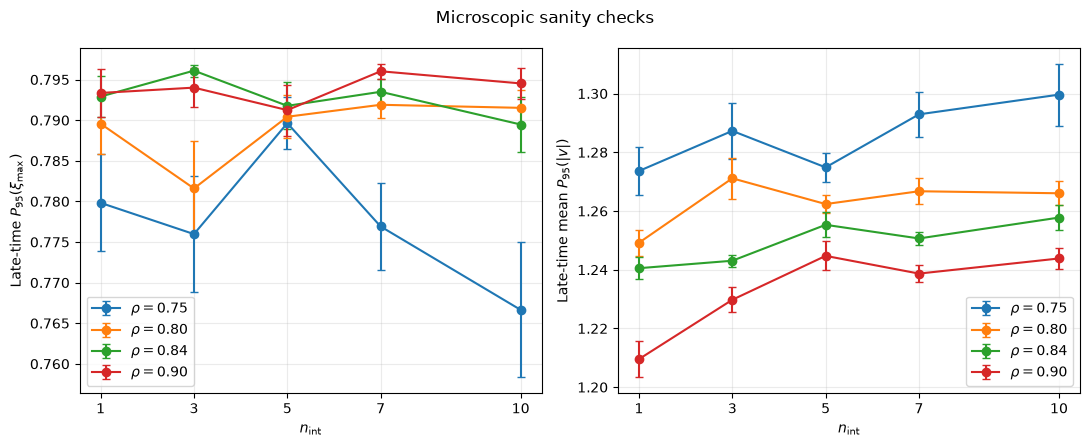

In [14]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4.5),
)

for rho in DENSITIES:
    subset_overlap = (
        overlap_summary[np.isclose(overlap_summary["rho"], rho)]
        .sort_values("n_int")
    )
    axes[0].errorbar(
        subset_overlap["n_int"],
        subset_overlap["p95_ximax_mean"],
        yerr=subset_overlap["p95_ximax_sem"],
        marker="o",
        capsize=3,
        label=fr"$\rho={rho:.2f}$",
    )

    subset_velocity = (
        velocity_summary[np.isclose(velocity_summary["rho"], rho)]
        .sort_values("n_int")
    )
    axes[1].errorbar(
        subset_velocity["n_int"],
        subset_velocity["p95_speed_mean"],
        yerr=subset_velocity["p95_speed_sem"],
        marker="o",
        capsize=3,
        label=fr"$\rho={rho:.2f}$",
    )

axes[0].set_xlabel(r"$n_{\rm int}$")
axes[0].set_ylabel(r"Late-time $P_{95}(\xi_{\max})$")
axes[0].set_xticks(N_INTS)
axes[0].legend()

axes[1].set_xlabel(r"$n_{\rm int}$")
axes[1].set_ylabel(r"Late-time mean $P_{95}(|v|)$")
axes[1].set_xticks(N_INTS)
axes[1].legend()

fig.suptitle("Microscopic sanity checks")
fig.tight_layout()
plt.savefig(figures_dir / "microscopic_sanity_checks.png", dpi=300)
plt.show()


## 6. Compact decision table

The table below combines only quantities needed to choose $n_{\rm int}$.

`macro_max_shift_to_10` is the largest, over the four densities and four
macroscopic observables, of

$$
\left|
\langle X\rangle_{n_{\rm int}}
-
\langle X\rangle_{10}
\right|.
$$

Because $n_{\rm int}=10$ is merely the largest tested value, this quantity is
a **plateau diagnostic**, not an error estimate.

`round_success_max_shift_to_10` performs the analogous comparison for the
**pooled** cell-level elongation success probability. The remaining columns report the
worst density for the microscopic safety diagnostics.


In [15]:
macro_decision = (
    macro_shift_to_10["overall_max"]
    .rename("macro_max_shift_to_10")
    .reset_index()
)

success_decision = (
    round_success_shift_to_10
    .reset_index()
)

overlap_decision = (
    overlap_summary
    .groupby("n_int")
    .agg(
        overlap_p95_worst=("p95_ximax_mean", "max"),
        overlap_max_worst=("max_ximax_mean", "max"),
        frac095_worst=("frac095_mean", "max"),
    )
    .reset_index()
)

velocity_decision = (
    velocity_summary
    .groupby("n_int")
    .agg(
        mean_speed_worst=("mean_speed_mean", "max"),
        p95_speed_worst=("p95_speed_mean", "max"),
        max_speed_worst=("max_speed_mean", "max"),
    )
    .reset_index()
)

rejection_decision = (
    deformation_per_seed
    .groupby(["n_int", "rho"])
    ["contraction_rejection_fraction"]
    .mean()
    .groupby("n_int")
    .max()
    .rename("contraction_rejection_worst")
    .reset_index()
)

decision_table = (
    macro_decision
    .merge(success_decision, on="n_int")
    .merge(overlap_decision, on="n_int")
    .merge(velocity_decision, on="n_int")
    .merge(rejection_decision, on="n_int")
    .sort_values("n_int")
    .set_index("n_int")
)

display(decision_table.round(4))


,macro_max_shift_to_10,round_success_max_shift_to_10,overlap_p95_worst,overlap_max_worst,frac095_worst,mean_speed_worst,p95_speed_worst,max_speed_worst,contraction_rejection_worst
n_int,,,,,,,,,
1,0.0834,0.0018,0.7934,0.7946,0.0,0.8980,1.2736,1.9291,0.0064
3,0.0523,0.0008,0.7961,0.7976,0.0,0.9150,1.2873,1.9318,0.0101
5,0.0512,0.0004,0.7918,0.7934,0.0,0.9098,1.2749,1.9436,0.0080
7,0.0280,0.0004,0.7960,0.7970,0.0,0.9276,1.2929,1.9564,0.0086
10,0.0000,0.0000,0.7945,0.7961,0.0,0.9258,1.2996,1.9498,0.0076


## 7. Final decision

The tested values separate naturally into three regimes.

- $n_{\rm int}=1$ is insufficient. Its late-time elongated fraction differs
  substantially from the large-$n_{\rm int}$ runs, with a maximum shift of
  about $0.083$ relative to $n_{\rm int}=10$.
- $n_{\rm int}=3$ captures most of the effect but retains a visible
  high-density dependence; the maximum $f_E$ shift relative to
  $n_{\rm int}=10$ is still about $0.033$.
- From $n_{\rm int}=5$ onward the observables tied most directly to the
  deformation rule are in a practical plateau. In particular, the maximum
  $f_E$ shift for $n_{\rm int}=5$ is only about $0.007$, and
  $S_{1,E}/N_E$ is likewise stable. The remaining differences in $P$ and
  $Q$ are non-monotonic across $5,7,10$, so they are not evidence for a
  systematic drift toward the $n_{\rm int}=10$ state.

The pooled elongation-success probability supports the same conclusion: after
removing the unequal-denominator artifact of the mean-of-ratios estimator, the
difference between $5$, $7$ and $10$ is small compared with the large
change from $1$ to $3$ and the remaining change from $3$ to $5$.

The microscopic controls do not provide a reason to prefer a larger value.
Overlap statistics, instantaneous velocities and contraction-overlap
rejections remain regular throughout the sweep.

Therefore the production value is fixed to

$$
\boxed{n_{\rm int}=5}
$$

or, in the implementation,

```python
cell_max_def_attempts = 5
```

This is a **practical model-parameter plateau**, not a numerical convergence
limit. We select the smallest value in that plateau because increasing the
number of sampled orientations changes little in the resulting collective
state while increasing the cost of every round-cell elongation call.


## Conclusions

The sensitivity study of the number of internal elongation proposals is
closed with

$$
\boxed{n_{\rm int}=5}
\qquad
\left(\texttt{cell\_max\_def\_attempts}=5\right).
$$

The main evidence is:

- $n_{\rm int}=1$ clearly under-samples admissible elongation orientations;
- $n_{\rm int}=3$ substantially reduces this effect but still modifies the
  high-density state;
- $n_{\rm int}=5,7,10$ form a practical plateau in the elongated fraction and
  elongated-cluster observable;
- the residual variation of polar and nematic order over $5,7,10$ is
  non-monotonic and is consistent with ensemble variability rather than a
  systematic dependence on $n_{\rm int}$;
- the pooled round-cell elongation success probability is already close to its
  large-$n_{\rm int}$ value at $n_{\rm int}=5$;
- successful elongations and contractions to the round state are nearly
  balanced at late times, confirming a dynamic phenotypic steady regime rather
  than one-way accumulation;
- overlap, velocity and contraction-safety diagnostics remain regular for all
  tested values.

No additional $n_{\rm int}$ simulations are warranted for the present model.
The next validation step is the deformation attempt period $T_{\rm def}$;
after that, the contraction overlap safety ratio $\xi_{\rm safe}$ can be
finalized.
